In [5]:
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from quartz.data import Grid
from quartz.dataprocessing import (
    kmeans_clustering,
    grid_abs_stddev,
    pair_overlap,
    calculate_pki_avg
)
from quartz.grids import to_dxgrid

def pair_overlap_arrays(
    reference, targets
):
    scores = []
    ref_grid = reference.astype(np.float64)

    for t in targets:
        np_grid = t.astype(np.float64)

        total_diff = np.sum(np.abs(np_grid - ref_grid))
        total_sum = np.sum(np.abs(np_grid)) + np.sum(np.abs(ref_grid))

        if total_sum == 0 or np.isinf(total_sum):
            scores.append(np.nan)
        else:
            scores.append(np.round(1 - (total_diff / total_sum), 4))

    return scores

# KMeans

In [14]:
grids: list[Grid] = pickle.load(open("grids.pkl", "rb"))
km_clusters = kmeans_clustering(grids, props=["RESP"], n_clusters=4)

In [15]:
# print("Calculating pKi average")
pki_avg = calculate_pki_avg(grids, props=["RESP"])
# print("Calculating standard deviation")
stdev = grid_abs_stddev(grids, props=["RESP"], means=pki_avg).npGrid["RESP"]

overlap_per_cluster: dict[str, list[float]] = {}
labels_flat = km_clusters.npGrid["RESP"]
for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    # print(f"Processing cluster {i}")
    indices = labels_flat == i
    masked_grids = [g.npGrid["RESP"][indices] * g.mol_data.pki for g in grids]
    # print(masked_grids[0].shape)


    masked_std = stdev[indices]
    
    # Save masked stdev to dx
    masked_std_grid = np.zeros_like(stdev)
    masked_std_grid[indices] = masked_std
    # print(masked_std_grid.shape)
    to_dxgrid(masked_std_grid, filename="std_cluster_" + str(i) + ".dx", origin=grids[0].grid_props["origin"], spacing=grids[0].grid_props["size"])
    
    if not masked_grids:
        continue

    # print("Calculating mean grid")
    mean_grid = np.mean(masked_grids, axis=0)
    # print("Calculating overlap btwn arrays")
    overlaps = pair_overlap_arrays(masked_std, masked_grids)
    overlap_per_cluster[str(i)] = overlaps

C:\Users\friedrich\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:2015: RuntimeWarning:

Degrees of freedom <= 0 for slice.



Writing grids\data_std_cluster_0.dx...
Writing grids\data_std_cluster_1.dx...
Writing grids\data_std_cluster_2.dx...
Writing grids\data_std_cluster_3.dx...


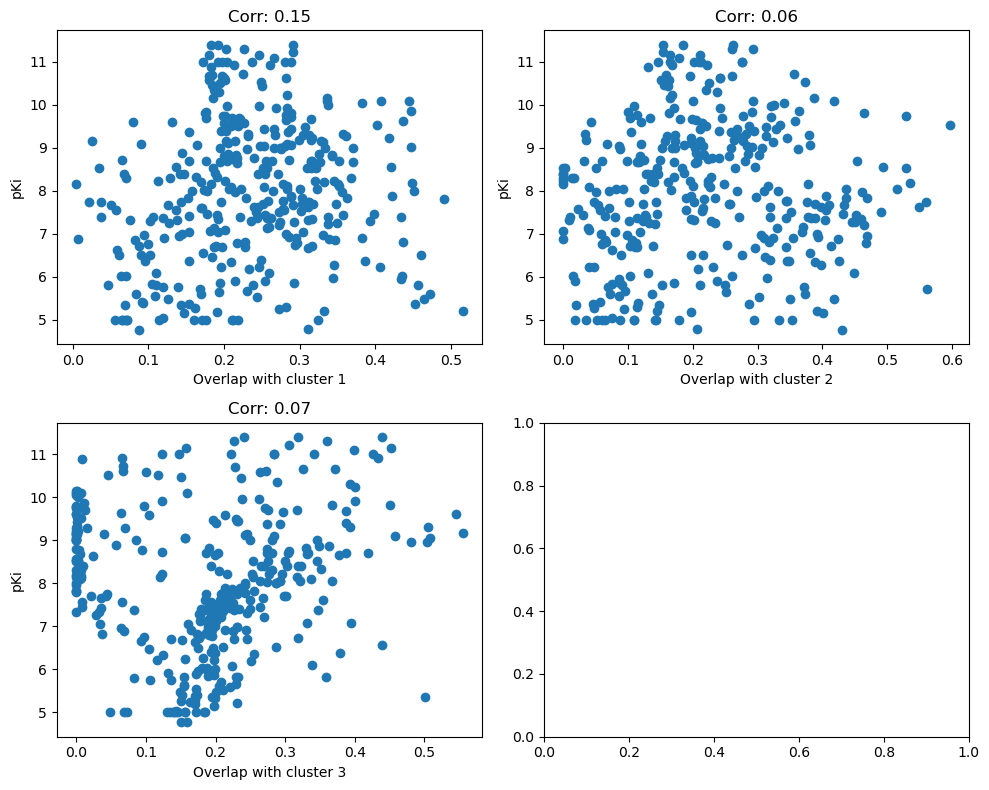

In [17]:
df = pd.DataFrame(overlap_per_cluster)
df["pKi"] = [g.mol_data.pki for g in grids]
df.dropna(inplace=True)
# df.sort_values(by="pKi", ascending=False)
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

# fig.suptitle("KMeans Clustering RESP Overlap vs pKi")

axs[0, 0].scatter(df["1"], df["pKi"])
axs[0, 0].set_xlabel("Overlap with cluster 1")
axs[0, 0].set_ylabel("pKi")
axs[0, 0].set_title(f"Corr: {df['1'].corr(df['pKi']).round(2)}")

axs[0, 1].scatter(df["2"], df["pKi"])
axs[0, 1].set_xlabel("Overlap with cluster 2")
axs[0, 1].set_ylabel("pKi")
axs[0, 1].set_title(f"Corr: {df['2'].corr(df['pKi']).round(2)}")

axs[1, 0].scatter(df["3"], df["pKi"])
axs[1, 0].set_xlabel("Overlap with cluster 3")
axs[1, 0].set_ylabel("pKi")
axs[1, 0].set_title(f"Corr: {df['3'].corr(df['pKi']).round(2)}")

# axs[1, 1].scatter(df["4"], df["pKi"])
# axs[1, 1].set_xlabel("Overlap with cluster 4")
# axs[1, 1].set_ylabel("pKi")
# axs[1, 1].set_title(f"Corr: {df['4'].corr(df['pKi']).round(2)}")

plt.tight_layout()
plt.show()

In [18]:
# Control which clusters to plot (exclude cluster 0 by default)
clusters_to_plot = [
    1,
    2,
    3,
    4,
    5,
]  # Modify this list to control which clusters are displayed

# Get cluster labels (3D grid shape)
labels = km_clusters.npGrid["RESP"]

# Generate grid coordinates based on the shape of the cluster data
shape = labels.shape
x_coords, y_coords, z_coords = np.meshgrid(
    np.arange(shape[0]), np.arange(shape[1]), np.arange(shape[2]), indexing="ij"
)

# Flatten all arrays for plotting
x_flat = x_coords.flatten()
y_flat = y_coords.flatten()
z_flat = z_coords.flatten()
labels_flat = labels.flatten()

# Filter to only include selected clusters
mask = np.isin(labels_flat, clusters_to_plot)
x_filtered = x_flat[mask]
y_filtered = y_flat[mask]
z_filtered = z_flat[mask]
labels_filtered = labels_flat[mask]

# Create a plotly 3D scatter plot with discrete colors for clusters
fig = px.scatter_3d(
    x=x_filtered,
    y=y_filtered,
    z=z_filtered,
    color=labels_filtered.astype(str),  # Convert to string for discrete colors
    title="K-Means Clustering of Grid Points",
    labels={"x": "X", "y": "Y", "z": "Z", "color": "Cluster"},
    opacity=0.6,
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(legend_title_text="Cluster")
fig.show()

# HDBSCAN

In [ ]:
from sklearn.cluster import HDBSCAN


hdb = HDBSCAN(min_cluster_size=10)
hdb.fit(np.array([g.npGrid["RESP"].flatten() for g in grids]))
hdb_labels = hdb.labels_.reshape(grids[0].npGrid["RESP"].shape)

c:\Users\friedrich\Documents\Uni\Major\quartz\.pixi\envs\default\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning:

The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.

